# Prediksi Volatilitas & Return IHSG (`^JKSE`) — Versi Revisi (Walk-Forward, Skala Konsisten, Idempoten)

Notebook ini memperbaiki masalah evaluasi di versi `maks_3`. Tujuan utamanya: **kesimpulan yang bisa dipertanggungjawabkan** dan **hasil yang sama setiap kali dijalankan ulang (idempoten)**.

## Ringkasan perbaikan

| # | Masalah di versi lama | Perbaikan di notebook ini | Rujukan |
|---|---|---|---|
| 1 | GARCH diuji pada skala varians return, hybrid dilatih pada skala Parkinson (beda ±1,4x) → perbandingan tidak adil | Proxy Parkinson diskalakan sekali (`c_train`, hanya dari data latih) ke skala close-to-close. **Semua model** dilatih dan diuji pada skala yang sama, tanpa kalibrasi khusus per model | Parkinson (1980); Patton (2011) |
| 2 | Model dipilih dari skor data uji (bias seleksi) | Data dibagi **latih / validasi / uji**. Hyperparameter dan model dipilih di validasi, data uji hanya untuk laporan akhir | Tashman (2000) |
| 3 | Satu split 80/20, tanpa refit | **Walk-forward** (expanding window, refit tiap 21 hari) untuk validasi maupun uji | Tashman (2000) |
| 4 | Benchmark lemah (varians konstan, tanpa HAR/GJR) | Benchmark: varians historis *expanding*, EWMA, **HAR-RV (log)**, **GARCH(1,1)-t**, **GJR-GARCH(1,1)-t** | Hansen & Lunde (2005); Corsi (2009); Glosten dkk. (1993) |
| 5 | "Akurasi rezim" 92,9% (menebak NORMAL terus juga 92,9%) | Precision, Recall, F1 dan AUC untuk kelas HIGH | — |
| 6 | "Akurasi harga 99%" dan "RMSE < 1%" (naif juga 99,2%) | **R²_OS** terhadap rata-rata historis, uji **Clark–West**, uji arah **Pesaran–Timmermann** terhadap baseline "selalu naik" | Campbell & Thompson (2008); Welch & Goyal (2008); Clark & West (2007); Pesaran & Timmermann (1992) |
| 7 | Prediksi "7 hari ke depan" sebenarnya memprediksi hari terakhir data (fitur lag tidak digeser ke hari depan) dan skalanya bercampur | Baris fitur untuk hari berikutnya dibangun benar; proyeksi volatilitas mean-reverting ke varians jangka panjang GARCH **pada skala yang sama** | Bollerslev (1986) |
| 8 | Tidak idempoten: unduh ulang tiap run, `datetime.now()` di JSON, tulis file langsung | Cache data lokal, tanggal akhir tetap, seed tetap, tanpa timestamp, tulis file atomik, ada uji idempotensi | — |

## Catatan penting
* **Waktu penggunaan prediksi:** fitur memakai return Dow Jones/EEM hari sebelumnya, yang baru tersedia ±04:00 WIB. Jadwalkan Azure Function **setelah penutupan pasar AS dan sebelum pembukaan BEI (09:00 WIB)**.
* Skala proxy (`c_train`) adalah **keputusan desain** agar model setara. Patton (2011) hanya menjamin urutan QLIKE/MSE benar bila proxy tidak bias terhadap varians sebenarnya. Karena itu hasil juga dilaporkan terhadap *squared return* (tidak bias, tetapi lebih berisik).
* Hasil boleh jadi **tidak lagi menunjukkan hybrid menang**. Itu hasil yang jujur, bukan kegagalan.

## Instalasi dependensi (jalankan sekali di paling awal)
Sel ini hanya memasang paket yang belum tersedia (idempoten). Setelah selesai, jika Colab meminta *restart runtime*, lakukan lalu jalankan ulang dari sel berikutnya.

In [1]:
import importlib, subprocess, sys

REQUIRED = {"arch": "arch", "yfinance": "yfinance", "sklearn": "scikit-learn",
            "scipy": "scipy", "pandas": "pandas", "numpy": "numpy",
            "matplotlib": "matplotlib", "joblib": "joblib"}
missing = [pip_name for mod, pip_name in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Memasang:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("[OK] Terpasang. Jika impor di sel berikutnya masih gagal, restart runtime lalu jalankan ulang.")
else:
    print("[OK] Semua dependensi sudah tersedia.")

Memasang: ['arch']
[OK] Terpasang. Jika impor di sel berikutnya masih gagal, restart runtime lalu jalankan ulang.


## 0. Import & konfigurasi (semua parameter di satu tempat)

In [2]:
import os, json, time, hashlib, warnings
import numpy as np
import pandas as pd
import joblib
from scipy import stats
from arch import arch_model
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
EPS = 1e-4  # lantai numerik untuk varians (%^2) agar QLIKE/log stabil

CFG = dict(
    TICKERS=['^JKSE', 'CL=F', 'GC=F', 'IDR=X', '^HSI', '^N225', '^DJI', 'EEM'],
    START_DATE="2018-01-01",
    END_DATE="2026-11-01",       # TETAP -> data identik tiap run (idempoten). Ubah sadar jika ingin data baru.
    TRAIN_FRAC=0.60, VAL_FRAC=0.20,   # sisanya (20%) = data uji
    REFIT_EVERY=21,              # refit walk-forward tiap ~1 bulan bursa
    HORIZON=7,
    N_FEAT_RET=14, N_FEAT_VOL=12,
    STRESS_Q=0.95,               # kuantil rezim risiko tinggi (dari data latih)
    EWMA_LAMBDA=0.94,
    GATE_ALPHA=0.05,             # syarat signifikansi Clark-West agar model ML return dipakai
    IDX_HOLIDAYS=[],             # isi dengan tanggal libur BEI resmi, contoh: ["2026-12-25"]
    CACHE_DIR="data_cache", OUT_DIR="outputs",
    FORCE_REFRESH=False,         # True = unduh ulang dari yfinance & timpa cache
    VERIFY_IDEMPOTENT=True,
)
os.makedirs(CFG["OUT_DIR"], exist_ok=True)

def atomic_write_text(path, text):
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        f.write(text)
    os.replace(tmp, path)

print("[OK] Konfigurasi dimuat. SEED =", SEED)

[OK] Konfigurasi dimuat. SEED = 42


## 1. Data: unduh sekali, simpan cache, lalu selalu baca dari cache

Pada run pertama data diunduh dari yfinance dan disimpan ke `data_cache/`. Run berikutnya membaca file yang sama, sehingga hasil tidak berubah walau Yahoo merevisi data. Set `FORCE_REFRESH=True` untuk mengunduh ulang. Sidik jari (hash) data dicetak dan disimpan di JSON sebagai bukti.

In [3]:
def load_raw(cfg):
    os.makedirs(cfg["CACHE_DIR"], exist_ok=True)
    path = os.path.join(cfg["CACHE_DIR"], f"raw_{cfg['START_DATE']}_{cfg['END_DATE']}.csv")
    source = "cache"
    if not os.path.exists(path) or cfg["FORCE_REFRESH"]:
        source = "yfinance"
        _download_to_cache(cfg, path)
    # SELALU baca dari file (termasuk tepat setelah unduhan) dengan round_trip,
    # agar run pertama dan run berikutnya memakai data yang bit-per-bit identik.
    return pd.read_csv(path, index_col=0, parse_dates=True, float_precision="round_trip"), path, source

def _download_to_cache(cfg, path):
    import yfinance as yf
    raw = yf.download(cfg["TICKERS"], start=cfg["START_DATE"], end=cfg["END_DATE"],
                      auto_adjust=True, progress=False, group_by="column")
    parts = []
    for t in cfg["TICKERS"]:
        d = raw.xs(t, axis=1, level=1).copy()
        d.columns = [f"{t}_{c.lower()}" for c in d.columns]
        parts.append(d)
    df = pd.concat(parts, axis=1).sort_index()
    tmp = path + ".tmp"
    df.to_csv(tmp)
    os.replace(tmp, path)

def clean_raw(df):
    df = df[~df.index.duplicated()].sort_index()
    df = df[df["^JKSE_close"].notna()]          # kalender = hari bursa BEI
    df = df.ffill(limit=3).dropna()             # isi libur bursa luar negeri maks 3 hari
    price_cols = [c for c in df.columns if not c.endswith("_volume")]
    return df[(df[price_cols] > 0).all(axis=1)]

df_raw, cache_path, source = load_raw(CFG)
df_raw = clean_raw(df_raw)
DATA_FP = hashlib.sha256(pd.util.hash_pandas_object(df_raw, index=True).values.tobytes()).hexdigest()

print(f"Sumber data   : {source} ({cache_path})")
print(f"Hari bursa    : {len(df_raw)}  ({df_raw.index[0].date()} s.d. {df_raw.index[-1].date()})")
print(f"Sidik jari    : {DATA_FP[:16]}...")

Sumber data   : yfinance (data_cache/raw_2018-01-01_2026-11-01.csv)
Hari bursa    : 2124  (2018-01-04 s.d. 2026-10-30)
Sidik jari    : c9a73672dbea8e17...


## 2. Fitur, target, dan pembagian latih / validasi / uji

**Target**
* `ret` = log-return harian IHSG (%).
* Proxy volatilitas = varians **Parkinson (1980)** dari High–Low, lalu dikalikan `c_train` agar sekala dengan varians close-to-close (Parkinson mengabaikan gap semalam sehingga cenderung lebih kecil). `c_train` dihitung **hanya dari data latih**.

**Fitur (semua lag t‑1)**: per instrumen — return, varians Parkinson, rata-rata return 5 hari, rata-rata return kuadrat 5 hari, perubahan volume (dibuang otomatis jika volume instrumen umumnya nol, seperti kurs); plus 4 fitur HAR milik IHSG.

**Baris hari berikutnya:** satu baris tambahan (hari bursa berikutnya) ditempelkan sebelum fitur dihitung. Dengan begitu fitur hari-depan terbentuk benar dari data terakhir. Versi lama tidak melakukan ini.

In [4]:
def park_var(h, l):
    ratio = np.maximum(h / np.maximum(l, 1e-8), 1.0)
    return 1e4 * np.log(ratio) ** 2 / (4.0 * np.log(2.0))

def build_frame(df, cfg):
    last = df.index[-1]
    next_day = pd.bdate_range(last + pd.Timedelta(days=1), periods=1, freq="C",
                              holidays=cfg["IDX_HOLIDAYS"])[0]
    ext = df.reindex(df.index.append(pd.DatetimeIndex([next_day])))   # baris terakhir = hari depan (NaN)
    F, skipped = {}, []
    for t in cfg["TICKERS"]:
        c, h, l, v = (ext[f"{t}_{k}"] for k in ("close", "high", "low", "volume"))
        r = 100.0 * np.log(c / c.shift(1))
        pv = park_var(h, l)
        F[f"{t}_ret_lag1"] = r.shift(1)
        F[f"{t}_park_var_lag1"] = pv.shift(1)
        F[f"{t}_ret_ma5_lag1"] = r.rolling(5).mean().shift(1)
        F[f"{t}_rv5_lag1"] = (r ** 2).rolling(5).mean().shift(1)
        if (df[f"{t}_volume"] > 0).mean() > 0.9:
            F[f"{t}_vol_chg_lag1"] = np.log((v + 1.0) / (v.shift(1) + 1.0)).shift(1)
        else:
            skipped.append(t)
    r1, p1 = F["^JKSE_ret_lag1"], F["^JKSE_park_var_lag1"]
    F["^JKSE_sq_ret_lag1"] = r1 ** 2
    F["^JKSE_rv22_lag1"] = (r1 ** 2).rolling(22).mean()
    F["^JKSE_park_ma5_lag1"] = p1.rolling(5).mean()
    F["^JKSE_park_ma22_lag1"] = p1.rolling(22).mean()
    X = pd.DataFrame(F, index=ext.index)

    c = ext["^JKSE_close"]
    T = pd.DataFrame({
        "close": c,
        "prev_close": c.shift(1),
        "ret": 100.0 * np.log(c / c.shift(1)),
        "park": park_var(ext["^JKSE_high"], ext["^JKSE_low"]),
    }, index=ext.index)

    first = int(X.notna().all(axis=1).values.argmax())   # buang baris awal (jendela rolling)
    X, T = X.iloc[first:], T.iloc[first:]
    assert X.notna().all().all(), "Fitur mengandung NaN setelah pemangkasan"
    assert T.iloc[:-1][["ret", "park"]].notna().all().all(), "Target mengandung NaN"
    return X, T, skipped

X, T, skipped_vol = build_frame(df_raw, CFG)
feature_names = list(X.columns)
N = len(X); n_real = N - 1                      # n_real = jumlah hari bursa nyata; indeks n_real = hari depan

R = T["ret"].to_numpy(copy=True)                # log-return (%), elemen terakhir NaN (hari depan)
PARK = T["park"].to_numpy(copy=True)
CLOSE = T["close"].to_numpy(copy=True)
PREV = T["prev_close"].to_numpy(copy=True)

i_tr = int(n_real * CFG["TRAIN_FRAC"])
i_va = int(n_real * (CFG["TRAIN_FRAC"] + CFG["VAL_FRAC"]))

# Skala proxy: HANYA dari data latih
c_train = float(np.mean(R[:i_tr] ** 2) / np.mean(PARK[:i_tr]))
TV = c_train * PARK                             # proxy utama (Parkinson terskala)
SQ = R ** 2                                     # proxy sekunder (squared return)
LOGTV = np.log(np.maximum(TV, EPS))
tau = float(np.quantile(np.sqrt(TV[:i_tr]), CFG["STRESS_Q"]))   # ambang rezim HIGH (dari data latih)

print(f"Fitur aktif       : {len(feature_names)}  (vol_chg dibuang untuk: {skipped_vol})")
print(f"Latih      [0,{i_tr})   : {T.index[0].date()} s.d. {T.index[i_tr-1].date()}  ({i_tr} hari)")
print(f"Validasi   [{i_tr},{i_va}) : {T.index[i_tr].date()} s.d. {T.index[i_va-1].date()}  ({i_va-i_tr} hari)")
print(f"Uji        [{i_va},{n_real}) : {T.index[i_va].date()} s.d. {T.index[n_real-1].date()}  ({n_real-i_va} hari)")
print(f"c_train = {c_train:.4f} | ambang rezim HIGH (tau, vol harian) = {tau:.4f}%")

Fitur aktif       : 43  (vol_chg dibuang untuk: ['IDR=X'])
Latih      [0,1260)   : 2018-02-06 s.d. 2023-04-12  (1260 hari)
Validasi   [1260,1680) : 2023-04-13 s.d. 2025-01-20  (420 hari)
Uji        [1680,2101) : 2025-01-21 s.d. 2026-10-30  (421 hari)
c_train = 1.4626 | ambang rezim HIGH (tau, vol harian) = 1.8213%


## 3. Seleksi fitur (hanya data latih)

Random Forest dilatih sekali pada **data latih saja**, lalu diambil fitur dengan importance tertinggi. Fitur varians (`park_var`, `rv`, `sq_ret`, `park_ma`) diberi transformasi log untuk model volatilitas, mengikuti praktik HAR-RV (Corsi, 2009). Pohon tidak terpengaruh, tetapi Ridge diuntungkan.

In [5]:
XA = X.to_numpy(copy=True)
VAR_MASK = np.array([any(k in n for k in ("park_var", "_rv", "sq_ret", "park_ma")) for n in feature_names])
XA_LOG = np.where(VAR_MASK, np.log(np.maximum(XA, EPS)), XA)

def top_features(Xm, y, k):
    rf = RandomForestRegressor(n_estimators=300, max_depth=6, min_samples_leaf=20,
                               random_state=SEED, n_jobs=1).fit(Xm, y)
    idx = np.argsort(-rf.feature_importances_, kind="stable")[:k]
    return [int(i) for i in idx], rf.feature_importances_[idx]

ret_idx, ret_imp = top_features(XA[:i_tr], R[:i_tr], CFG["N_FEAT_RET"])
vol_idx, vol_imp = top_features(XA_LOG[:i_tr], LOGTV[:i_tr], CFG["N_FEAT_VOL"])
ret_features = [feature_names[i] for i in ret_idx]
vol_features = [feature_names[i] for i in vol_idx]
XR = XA[:, ret_idx]            # fitur model return
XV = XA_LOG[:, vol_idx]        # fitur model volatilitas (di luar fitur GARCH)

display(pd.DataFrame({"Fitur Return": ret_features, "Importance": ret_imp}).round(4))
display(pd.DataFrame({"Fitur Volatilitas": vol_features, "Importance": vol_imp}).round(4))

,Fitur Return,Importance
0,EEM_ret_lag1,0.1492
1,^DJI_ret_lag1,0.1419
2,^DJI_ret_ma5_lag1,0.0527
3,^DJI_rv5_lag1,0.0519
4,IDR=X_park_var_lag1,0.0401
5,EEM_ret_ma5_lag1,0.0349
6,CL=F_park_var_lag1,0.0249
7,^N225_ret_lag1,0.0230
8,GC=F_rv5_lag1,0.0220
9,^HSI_ret_ma5_lag1,0.0213


,Fitur Volatilitas,Importance
0,^JKSE_park_var_lag1,0.3376
1,^JKSE_park_ma5_lag1,0.1562
2,^JKSE_park_ma22_lag1,0.0800
3,^DJI_park_var_lag1,0.0453
4,EEM_rv5_lag1,0.0303
5,^JKSE_ret_ma5_lag1,0.0290
6,^JKSE_rv5_lag1,0.0280
7,EEM_park_var_lag1,0.0219
8,^JKSE_rv22_lag1,0.0214
9,IDR=X_park_var_lag1,0.0198


## 4. Model volatilitas (satu mesin walk-forward untuk validasi, uji, dan produksi)

Semua model memprediksi **varians hari t dari informasi sampai t‑1**, pada skala yang sama:

| Model | Keterangan | Rujukan |
|---|---|---|
| Historical (expanding) | Varians return seluruh riwayat | — |
| EWMA 0.94 | RiskMetrics | — |
| HAR-log | Regresi log-varians pada rata-rata 1, 5, 22 hari + smearing | Corsi (2009); Duan (1983) |
| GARCH(1,1)-t | Benchmark utama | Bollerslev (1986, 1987); Hansen & Lunde (2005) |
| GJR-GARCH(1,1)-t | GARCH dengan efek asimetris | Glosten dkk. (1993) |
| Hybrid GARCH + Ridge / RF / HGB | Prediksi GARCH sebagai fitur + fitur makro terpilih, target log-varians + smearing | — |

GARCH, GJR, dan model ML **dilatih ulang tiap 21 hari** pada seluruh riwayat sampai saat itu (expanding window). Di antara dua refit, parameter tetap dan rekursi varians memakai return aktual yang sudah teramati, jadi tidak ada kebocoran.

In [6]:
BASELINES = ["Historical (expanding)", "EWMA 0.94", "HAR-log", "GARCH(1,1)-t", "GJR-GARCH(1,1)-t"]

def qlike(y, f):
    y = np.maximum(np.asarray(y, float), EPS); f = np.maximum(np.asarray(f, float), EPS)
    return y / f - np.log(y / f) - 1.0

def dm_test(loss_model, loss_bench, h=1):
    """Diebold-Mariano (1995), HAC Bartlett, koreksi Harvey-Leybourne-Newbold (1997).
    Statistik negatif = model lebih baik dari benchmark. p-value dua sisi."""
    d = np.asarray(loss_model, float) - np.asarray(loss_bench, float)
    Tn = len(d); md = d.mean(); dd = d - md
    L = max(h - 1, int(np.floor(4.0 * (Tn / 100.0) ** (2.0 / 9.0))))
    lr = np.mean(dd ** 2)
    for k in range(1, L + 1):
        lr += 2.0 * (1.0 - k / (L + 1.0)) * np.mean(dd[k:] * dd[:-k])
    se = np.sqrt(max(lr / Tn, 1e-12))
    dm = md / se * np.sqrt((Tn + 1.0 - 2.0 * h + h * (h - 1.0) / Tn) / Tn)
    return float(dm), float(2.0 * (1.0 - stats.t.cdf(abs(dm), df=Tn - 1)))

def fit_garch(r, kind):
    spec = arch_model(r, mean="Constant", vol="GARCH", p=1, o=(1 if kind == "gjr" else 0), q=1,
                      dist="t", rescale=False)
    res = spec.fit(disp="off", update_freq=0)
    p = res.params
    alpha, beta, omega = float(p["alpha[1]"]), float(p["beta[1]"]), float(p["omega"])
    gamma = float(p["gamma[1]"]) if kind == "gjr" else 0.0
    pers = alpha + 0.5 * gamma + beta
    unc = omega / (1.0 - pers) if pers < 0.999 else float(np.var(r))
    return dict(mu=float(p["mu"]), omega=omega, alpha=alpha, beta=beta, gamma=gamma,
                nu=float(p["nu"]), persist=float(pers), uncond=float(unc),
                cond_var=np.asarray(res.conditional_volatility, float) ** 2)

def garch_extend(fi, r_all, s, e):
    """Varians satu-langkah untuk hari s..e-1 (parameter tetap, rekursi memakai return aktual)."""
    h_prev, out = fi["cond_var"][-1], np.empty(e - s)
    for j, t in enumerate(range(s, e)):
        ep = r_all[t - 1] - fi["mu"]
        h = fi["omega"] + (fi["alpha"] + fi["gamma"] * (ep < 0)) * ep ** 2 + fi["beta"] * h_prev
        out[j] = h; h_prev = h
    return out

# ---- Benchmark global (hanya memakai informasi sampai t-1) ----
HIST = pd.Series(R).expanding(min_periods=30).var().shift(1).to_numpy(copy=True)
EW = np.empty(N); EW[:30] = np.var(R[:30], ddof=1)
for t in range(30, N):
    EW[t] = CFG["EWMA_LAMBDA"] * EW[t - 1] + (1.0 - CFG["EWMA_LAMBDA"]) * R[t - 1] ** 2
_tv = pd.Series(TV)
HARX = np.column_stack([
    np.log(np.maximum(_tv.shift(1), EPS)),
    np.log(np.maximum(_tv.shift(1).rolling(5).mean(), EPS)),
    np.log(np.maximum(_tv.shift(1).rolling(22).mean(), EPS)),
]).astype(float)

def wf_vol(s0, s1, ml_specs, store=None):
    """Walk-forward volatilitas untuk hari s0..s1-1. Mengembalikan (prediksi, aux)."""
    K = CFG["REFIT_EVERY"]
    names = BASELINES + list(ml_specs)
    out = {n: np.full(s1 - s0, np.nan) for n in names}
    aux = {"uncond": np.full(s1 - s0, np.nan), "persist": np.full(s1 - s0, np.nan)}
    prev = {}
    for s in range(s0, s1, K):
        e = min(s + K, s1); sl = slice(s - s0, e - s0)
        out["Historical (expanding)"][sl] = HIST[s:e]
        out["EWMA 0.94"][sl] = EW[s:e]
        fits = {}
        for kind in ("garch", "gjr"):
            try:
                fits[kind] = fit_garch(R[:s], kind); prev[kind] = fits[kind]
            except Exception:
                fits[kind] = prev[kind]            # konvergensi gagal -> pakai fit sebelumnya
        g_ext = garch_extend(fits["garch"], R, s, e)
        out["GARCH(1,1)-t"][sl] = g_ext
        out["GJR-GARCH(1,1)-t"][sl] = garch_extend(fits["gjr"], R, s, e)
        aux["uncond"][sl] = fits["garch"]["uncond"]
        aux["persist"][sl] = fits["garch"]["persist"]
        # HAR-log (OLS) + smearing Duan
        m = np.isfinite(HARX[:s]).all(axis=1)
        A = np.column_stack([np.ones(m.sum()), HARX[:s][m]]); yv = LOGTV[:s][m]
        coef = np.linalg.lstsq(A, yv, rcond=None)[0]
        sm_har = float(np.mean(np.exp(yv - A @ coef)))
        out["HAR-log"][sl] = np.exp(np.column_stack([np.ones(e - s), HARX[s:e]]) @ coef) * sm_har
        # Hybrid GARCH + ML
        g_all = np.concatenate([fits["garch"]["cond_var"], g_ext])
        Xaug = np.column_stack([np.log(np.maximum(g_all, EPS)), XV[:e]])
        ml_store = {}
        for name, factory in ml_specs.items():
            mdl = factory().fit(Xaug[:s], LOGTV[:s])
            sm = float(np.mean(np.exp(LOGTV[:s] - mdl.predict(Xaug[:s]))))
            out[name][sl] = np.exp(mdl.predict(Xaug[s:e])) * sm
            ml_store[name] = (mdl, sm)
        if store is not None:
            store.update(garch=fits["garch"], gjr=fits["gjr"], har=(coef, sm_har), ml=ml_store)
    return out, aux

def mk_ridge(a): return lambda: Pipeline([("sc", StandardScaler()), ("m", Ridge(alpha=a))])
def mk_rf(d, leaf, n=200):
    return lambda: RandomForestRegressor(n_estimators=n, max_depth=d, min_samples_leaf=leaf,
                                         random_state=SEED, n_jobs=1)
def mk_hgb(lr, d, it=80):
    return lambda: HistGradientBoostingRegressor(learning_rate=lr, max_depth=d, max_iter=it,
                                                 l2_regularization=2.0, random_state=SEED)

VOL_GRID = {
    "Hybrid GARCH+Ridge": {f"alpha={a}": mk_ridge(a) for a in (1.0, 10.0, 100.0)},
    "Hybrid GARCH+RF":    {f"depth={d},leaf={l}": mk_rf(d, l) for d in (3, 5) for l in (20, 40)},
    "Hybrid GARCH+HGB":   {f"lr={lr},depth={d}": mk_hgb(lr, d) for lr in (0.03, 0.06) for d in (2, 3)},
}
print("[OK] Mesin walk-forward volatilitas siap.")

[OK] Mesin walk-forward volatilitas siap.


## 5. Pemilihan model volatilitas di **data validasi** (bukan data uji)

Untuk tiap keluarga hybrid dipilih hyperparameter dengan QLIKE validasi terkecil. Lalu pemenang keseluruhan = model (baseline atau hybrid) dengan QLIKE validasi terkecil. QLIKE dan MSE dipilih karena tetap memberi urutan model yang benar walau proxy volatilitas berisik (Patton, 2011).

In [7]:
t0 = time.perf_counter()
specs_val = {f"{fam}|{k}": f for fam, g in VOL_GRID.items() for k, f in g.items()}
val_fc, _ = wf_vol(i_tr, i_va, specs_val)
val_q = pd.Series({n: float(qlike(TV[i_tr:i_va], f).mean()) for n, f in val_fc.items()})

best_vol_specs, best_vol_cfg = {}, {}
for fam, grid in VOL_GRID.items():
    cand = {k: val_q[f"{fam}|{k}"] for k in grid}
    kbest = min(cand, key=cand.get)
    best_vol_specs[fam] = grid[kbest]; best_vol_cfg[fam] = kbest

val_summary = pd.Series({**{b: val_q[b] for b in BASELINES},
                         **{fam: val_q[f"{fam}|{best_vol_cfg[fam]}"] for fam in best_vol_specs}})
winner_vol = str(val_summary.idxmin())
print(f"Waktu seleksi volatilitas: {time.perf_counter() - t0:.1f} dtk")
print("Konfigurasi hybrid terpilih (validasi):", best_vol_cfg)
display(val_summary.sort_values().rename("QLIKE validasi").to_frame().round(4))
print(f"[PEMENANG VOLATILITAS (validasi)] : {winner_vol}")

Waktu seleksi volatilitas: 164.1 dtk
Konfigurasi hybrid terpilih (validasi): {'Hybrid GARCH+Ridge': 'alpha=100.0', 'Hybrid GARCH+RF': 'depth=5,leaf=20', 'Hybrid GARCH+HGB': 'lr=0.03,depth=3'}


,QLIKE validasi
Hybrid GARCH+Ridge,0.2405
Hybrid GARCH+HGB,0.2429
Hybrid GARCH+RF,0.2500
HAR-log,0.2544
"GARCH(1,1)-t",0.2639
"GJR-GARCH(1,1)-t",0.2663
EWMA 0.94,0.3606
Historical (expanding),0.3946


[PEMENANG VOLATILITAS (validasi)] : Hybrid GARCH+Ridge


## 6. Evaluasi akhir volatilitas pada **data uji** (walk-forward, sekali jalan)

* **Tabel A** — proxy utama: Parkinson terskala. **Tabel B** — squared return (tidak bias, lebih berisik).
* Tidak ada kalibrasi khusus per model; semua pada skala yang sama.
* `DM` = Diebold–Mariano HAC. Statistik **negatif** = model lebih baik dari benchmark; `p < 0,05` = beda signifikan.
* Rezim HIGH: Precision / Recall / F1 / AUC. Hitung juga *base rate* agar jelas bahwa "menebak NORMAL terus" bukan prestasi.

In [8]:
test_fc, test_aux = wf_vol(i_va, n_real, best_vol_specs)

SHORT = {"GARCH(1,1)-t": "GARCH", "HAR-log": "HAR"}

def eval_vol_table(fc, proxy, benches=("GARCH(1,1)-t", "HAR-log")):
    act_high = np.sqrt(proxy) > tau
    rows = []
    for n, f in fc.items():
        ql = qlike(proxy, f)
        pred_high = np.sqrt(f) > tau
        tp = int((pred_high & act_high).sum())
        prec = tp / pred_high.sum() if pred_high.sum() > 0 else np.nan
        rec = tp / act_high.sum() if act_high.sum() > 0 else np.nan
        f1 = 2 * prec * rec / (prec + rec) if (np.isfinite(prec) and np.isfinite(rec) and prec + rec > 0) else np.nan
        auc = roc_auc_score(act_high, f) if 0 < act_high.sum() < len(act_high) else np.nan
        row = {"Model": n, "QLIKE": ql.mean(),
               "RMSE Vol (%)": np.sqrt(np.mean((np.sqrt(proxy) - np.sqrt(f)) ** 2)),
               "MSE Varians": np.mean((proxy - f) ** 2),
               "Prec HIGH": prec, "Recall HIGH": rec, "F1 HIGH": f1, "AUC HIGH": auc}
        for b in benches:
            short = SHORT[b]
            if n == b:
                row[f"DM vs {short}"], row[f"p vs {short}"] = np.nan, np.nan
            else:
                row[f"DM vs {short}"], row[f"p vs {short}"] = dm_test(ql, qlike(proxy, fc[b]))
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model").sort_values("QLIKE")

y_te_tv, y_te_sq = TV[i_va:n_real], SQ[i_va:n_real]
tab_A = eval_vol_table(test_fc, y_te_tv)
tab_B = eval_vol_table(test_fc, y_te_sq)
base_rate = float(np.mean(np.sqrt(y_te_tv) > tau))
print(f"Base rate hari HIGH di data uji (proxy utama): {base_rate*100:.1f}%  -> menebak 'NORMAL' terus = {100*(1-base_rate):.1f}% akurasi")
print("\n=== TABEL A: Proxy utama (Parkinson terskala) ===")
display(tab_A.round(4))
print("\n=== TABEL B: Proxy sekunder (squared return) ===")
display(tab_B.round(4))

Base rate hari HIGH di data uji (proxy utama): 16.4%  -> menebak 'NORMAL' terus = 83.6% akurasi

=== TABEL A: Proxy utama (Parkinson terskala) ===


,QLIKE,RMSE Vol (%),MSE Varians,Prec HIGH,Recall HIGH,F1 HIGH,AUC HIGH,DM vs GARCH,p vs GARCH,DM vs HAR,p vs HAR
Model,,,,,,,,,,,
HAR-log,0.4958,0.7145,16.2203,0.5102,0.3623,0.4237,0.8085,-1.9240,0.0550,NaN,NaN
Hybrid GARCH+RF,0.5080,0.7071,15.9505,0.5778,0.3768,0.4561,0.8111,-1.8015,0.0723,0.6113,0.5413
Hybrid GARCH+Ridge,0.5095,0.6966,15.4575,0.6170,0.4203,0.5000,0.8162,-1.8006,0.0725,0.8205,0.4124
Hybrid GARCH+HGB,0.5495,0.7217,16.3638,0.6098,0.3623,0.4545,0.8043,-0.5924,0.5539,2.0232,0.0437
"GJR-GARCH(1,1)-t",0.5576,0.7914,18.3887,0.4568,0.5362,0.4933,0.7922,-1.0614,0.2891,1.3819,0.1677
"GARCH(1,1)-t",0.5753,0.7838,17.5139,0.4342,0.4783,0.4552,0.7715,NaN,NaN,1.9240,0.0550
EWMA 0.94,0.6563,0.8452,18.0561,0.3077,0.4638,0.3699,0.7211,2.1817,0.0297,2.8665,0.0044
Historical (expanding),1.0296,0.8669,20.1798,NaN,0.0000,NaN,0.5714,2.5511,0.0111,3.1545,0.0017



=== TABEL B: Proxy sekunder (squared return) ===


,QLIKE,RMSE Vol (%),MSE Varians,Prec HIGH,Recall HIGH,F1 HIGH,AUC HIGH,DM vs GARCH,p vs GARCH,DM vs HAR,p vs HAR
Model,,,,,,,,,,,
HAR-log,1.6176,1.1621,89.0542,0.3265,0.2319,0.2712,0.7635,-1.5449,0.1231,NaN,NaN
Hybrid GARCH+Ridge,1.6657,1.1367,87.7654,0.4255,0.2899,0.3448,0.7668,-1.5893,0.1127,0.8098,0.4185
Hybrid GARCH+RF,1.6934,1.1415,88.3967,0.3778,0.2464,0.2982,0.7695,-1.0893,0.2766,0.9895,0.3230
Hybrid GARCH+HGB,1.7564,1.1430,88.3813,0.4146,0.2464,0.3091,0.7658,-0.6756,0.4996,1.4810,0.1393
"GJR-GARCH(1,1)-t",1.7656,1.2345,91.4901,0.3210,0.3768,0.3467,0.7432,-1.7978,0.0729,1.1374,0.2560
"GARCH(1,1)-t",1.8608,1.2336,91.0110,0.3289,0.3623,0.3448,0.7295,NaN,NaN,1.5449,0.1231
EWMA 0.94,1.9629,1.2719,91.0095,0.2885,0.4348,0.3468,0.6922,1.9247,0.0549,1.7121,0.0876
Historical (expanding),2.3509,1.2231,93.5898,NaN,0.0000,NaN,0.5445,1.8669,0.0626,3.0099,0.0028


## 7. Proyeksi volatilitas multi-horizon (h = 1…7)

Varians hari ke‑k: $h_{t+k|t} = \bar\sigma^2 + (\alpha+\beta)^{k-1}(h_{t+1|t}-\bar\sigma^2)$ (Bollerslev, 1986). Model hybrid, HAR, dan GJR memakai ramalan 1-harinya sebagai titik awal lalu **mean-reverting ke varians jangka panjang GARCH pada skala yang sama**. Historical dan EWMA diproyeksikan datar. Varians kumulatif h hari dibandingkan dengan jumlah proxy h hari nyata (origin yang tumpang tindih → DM memakai lag HAC ≥ h‑1).

In [9]:
FLAT = ("Historical (expanding)", "EWMA 0.94")

def cum_var_forecast(name, h1, unc, per, h):
    if name in FLAT:
        return h * h1
    S = (1.0 - per ** h) / (1.0 - per)
    return h * unc + (h1 - unc) * S

def multi_h_eval(fc, aux, proxy, H=7):
    unc, per = aux["uncond"], np.clip(aux["persist"], 0.0, 0.9999)
    Tn = len(proxy)
    q, rm, dmp = {}, {}, {}
    for h in range(1, H + 1):
        m = Tn - h + 1
        act = np.array([proxy[t:t + h].sum() for t in range(m)])
        fg = cum_var_forecast("GARCH(1,1)-t", fc["GARCH(1,1)-t"][:m], unc[:m], per[:m], h)
        ql_g = qlike(act, fg)
        for n, f1 in fc.items():
            f = cum_var_forecast(n, f1[:m], unc[:m], per[:m], h)
            q.setdefault(n, {})[f"h={h}"] = qlike(act, f).mean()
            rm.setdefault(n, {})[f"h={h}"] = np.sqrt(np.mean((np.sqrt(act) - np.sqrt(f)) ** 2))
            if n == winner_vol and n != "GARCH(1,1)-t":
                dmp[f"h={h}"] = dm_test(qlike(act, f), ql_g, h=h)[1]
    return pd.DataFrame(q).T, pd.DataFrame(rm).T, dmp

mh_q, mh_rmse, mh_dm = multi_h_eval(test_fc, test_aux, y_te_tv, CFG["HORIZON"])
print("=== QLIKE varians kumulatif h hari (lebih kecil = lebih baik) ===")
display(mh_q.round(4))
print("=== RMSE volatilitas kumulatif (%) ===")
display(mh_rmse.round(4))
if mh_dm:
    print(f"p-value DM {winner_vol} vs GARCH(1,1)-t per horizon:", {k: round(v, 4) for k, v in mh_dm.items()})

=== QLIKE varians kumulatif h hari (lebih kecil = lebih baik) ===


,h=1,h=2,h=3,h=4,h=5,h=6,h=7
Historical (expanding),1.0296,0.9018,0.8427,0.8098,0.7859,0.7665,0.7514
EWMA 0.94,0.6563,0.6637,0.6610,0.6771,0.6976,0.7056,0.7180
HAR-log,0.4958,0.4153,0.3836,0.3753,0.3907,0.3990,0.4127
"GARCH(1,1)-t",0.5753,0.5689,0.5572,0.5607,0.5704,0.5680,0.5733
"GJR-GARCH(1,1)-t",0.5576,0.5488,0.5373,0.5406,0.5494,0.5482,0.5616
Hybrid GARCH+Ridge,0.5095,0.4566,0.4363,0.4412,0.4603,0.4678,0.4883
Hybrid GARCH+RF,0.5080,0.4571,0.4418,0.4401,0.4634,0.4734,0.4941
Hybrid GARCH+HGB,0.5495,0.5000,0.4817,0.4789,0.4974,0.5026,0.5200


=== RMSE volatilitas kumulatif (%) ===


,h=1,h=2,h=3,h=4,h=5,h=6,h=7
Historical (expanding),0.8669,1.1453,1.3544,1.5304,1.6820,1.8163,1.9391
EWMA 0.94,0.8452,1.0955,1.3102,1.4967,1.6702,1.8223,1.9596
HAR-log,0.7145,0.8978,1.0507,1.1922,1.3286,1.4477,1.5620
"GARCH(1,1)-t",0.7838,1.0088,1.2154,1.3921,1.5594,1.6991,1.8200
"GJR-GARCH(1,1)-t",0.7914,1.0160,1.2276,1.4103,1.5846,1.7276,1.8510
Hybrid GARCH+Ridge,0.6966,0.8807,1.0495,1.2086,1.3574,1.4895,1.6142
Hybrid GARCH+RF,0.7071,0.9024,1.0723,1.2290,1.3767,1.5044,1.6274
Hybrid GARCH+HGB,0.7217,0.9270,1.1053,1.2649,1.4143,1.5435,1.6683


p-value DM Hybrid GARCH+Ridge vs GARCH(1,1)-t per horizon: {'h=1': 0.0725, 'h=2': 0.0786, 'h=3': 0.0814, 'h=4': 0.0993, 'h=5': 0.107, 'h=6': 0.1135, 'h=7': 0.1373}


## 8. Model return: benchmark harus **rata-rata historis**, bukan harga naif

Return harian sangat sulit diprediksi (Welch & Goyal, 2008). Karena itu:
* Benchmark: **rata-rata historis expanding** dan **nol** (random walk).
* Metrik utama: **R²_OS** terhadap rata-rata historis (Campbell & Thompson, 2008). Nilai > 0 berarti model mengalahkan benchmark.
* Signifikansi: uji **Clark–West (2007)** (model bersarang; DM biasa terlalu konservatif). Satu sisi.
* Arah: akurasi vs baseline **"selalu naik"**, plus uji **Pesaran–Timmermann (1992)**. Hasil `NaN` berarti model hanya menebak satu arah.
* Harga: RMSE poin vs naif (harga = harga kemarin). "Akurasi harga 99%" tidak dilaporkan karena menyesatkan.

Seleksi model memakai validasi, lalu **gerbang produksi**: model ML dipakai hanya jika di data uji R²_OS > 0 dan p Clark–West < 0,05. Jika tidak, produksi memakai rata-rata historis.

In [10]:
MEANX = pd.Series(R).expanding(min_periods=30).mean().shift(1).to_numpy(copy=True)

def mk_mlp():
    return TransformedTargetRegressor(
        regressor=Pipeline([("sc", StandardScaler()),
                            ("m", MLPRegressor(hidden_layer_sizes=(32, 16), alpha=50.0, max_iter=300,
                                               early_stopping=True, random_state=SEED))]),
        transformer=StandardScaler())

RET_GRID = {
    "Ridge": {f"alpha={a}": mk_ridge(a) for a in (10.0, 100.0, 1000.0)},
    "Random Forest": {f"depth={d},leaf={l}": mk_rf(d, l) for d in (3, 5) for l in (20, 50)},
    "HistGradientBoosting": {"lr=0.03,depth=2": mk_hgb(0.03, 2, 60)},
    "MLP": {"default": mk_mlp},
    "Ensemble RF+MLP": {"default": lambda: VotingRegressor([("rf", mk_rf(3, 50)()), ("mlp", mk_mlp())])},
}

def wf_ret(s0, s1, specs, store=None):
    K = CFG["REFIT_EVERY"]
    out = {n: np.full(s1 - s0, np.nan) for n in specs}
    for s in range(s0, s1, K):
        e = min(s + K, s1); sl = slice(s - s0, e - s0)
        for name, factory in specs.items():
            mdl = factory().fit(XR[:s], R[:s])
            out[name][sl] = mdl.predict(XR[s:e])
            if store is not None:
                store[name] = mdl
    return out

def pesaran_timmermann(y_up, x_up):
    y, x = np.asarray(y_up, bool), np.asarray(x_up, bool); n = len(y)
    py, px, ph = y.mean(), x.mean(), (y == x).mean()
    if px in (0.0, 1.0) or py in (0.0, 1.0):
        return np.nan, np.nan
    ps = py * px + (1 - py) * (1 - px)
    v_ph = ps * (1 - ps) / n
    v_ps = ((2 * py - 1) ** 2 * px * (1 - px) + (2 * px - 1) ** 2 * py * (1 - py)
            + 4 * py * px * (1 - py) * (1 - px) / n) / n
    den = v_ph - v_ps
    if den <= 0:
        return np.nan, np.nan
    z = (ph - ps) / np.sqrt(den)
    return float(z), float(1.0 - stats.norm.cdf(z))

def eval_ret_table(fc, idx0, idx1):
    y, mb = R[idx0:idx1], MEANX[idx0:idx1]
    prev, close = PREV[idx0:idx1], CLOSE[idx0:idx1]
    sse_b = np.sum((y - mb) ** 2)
    up_rate = float(np.mean(y > 0))
    rmse_naive_px = float(np.sqrt(np.mean((close - prev) ** 2)))
    allf = {"Nol (random walk)": np.zeros_like(y), "Rata-rata historis": mb, **fc}
    rows = []
    for n, f in allf.items():
        e = y - f
        adj = (y - mb) ** 2 - (e ** 2 - (mb - f) ** 2)
        sd = adj.std(ddof=1)
        p_cw = float(1.0 - stats.norm.cdf(adj.mean() / (sd / np.sqrt(len(adj))))) if sd > 1e-12 else np.nan
        z_pt, p_pt = pesaran_timmermann(y > 0, f > 0)
        px_pred = prev * np.exp(f / 100.0)
        rows.append({"Model": n, "RMSE Return (%)": np.sqrt(np.mean(e ** 2)),
                     "R2_OS vs Rata2 Historis": 1.0 - np.sum(e ** 2) / sse_b,
                     "p Clark-West (1 sisi)": p_cw,
                     "Akurasi Arah (%)": 100 * np.mean(np.sign(f) == np.sign(y)),
                     "Baseline Selalu-Naik (%)": 100 * up_rate,
                     "p Pesaran-Timmermann": p_pt,
                     "RMSE Harga (poin)": np.sqrt(np.mean((close - px_pred) ** 2)),
                     "RMSE Harga Naif (poin)": rmse_naive_px})
    return pd.DataFrame(rows).set_index("Model")

# ---- Seleksi di validasi ----
t0 = time.perf_counter()
specs_rv = {f"{fam}|{k}": f for fam, g in RET_GRID.items() for k, f in g.items()}
rv_fc = wf_ret(i_tr, i_va, specs_rv)
rv_tab = eval_ret_table(rv_fc, i_tr, i_va)
best_ret_specs, best_ret_cfg = {}, {}
for fam, grid in RET_GRID.items():
    cand = {k: rv_tab.loc[f"{fam}|{k}", "R2_OS vs Rata2 Historis"] for k in grid}
    kbest = max(cand, key=cand.get)
    best_ret_specs[fam] = grid[kbest]; best_ret_cfg[fam] = kbest
val_r2 = pd.Series({"Rata-rata historis": 0.0,
                    **{fam: rv_tab.loc[f"{fam}|{best_ret_cfg[fam]}", "R2_OS vs Rata2 Historis"] for fam in best_ret_specs}})
winner_ret = str(val_r2.idxmax())
print(f"Waktu seleksi return: {time.perf_counter() - t0:.1f} dtk | Konfigurasi terpilih:", best_ret_cfg)
display(val_r2.sort_values(ascending=False).rename("R2_OS validasi").to_frame().round(5))
print(f"[PEMENANG RETURN (validasi)] : {winner_ret}")

# ---- Evaluasi akhir di data uji ----
rt_fc = wf_ret(i_va, n_real, best_ret_specs)
tab_R = eval_ret_table(rt_fc, i_va, n_real)
print("\n=== EVALUASI RETURN PADA DATA UJI (walk-forward) ===")
display(tab_R.round(4))

ml_return_enabled = False
if winner_ret != "Rata-rata historis":
    r_ = tab_R.loc[winner_ret]
    ml_return_enabled = bool(r_["R2_OS vs Rata2 Historis"] > 0 and r_["p Clark-West (1 sisi)"] < CFG["GATE_ALPHA"])
print(f"\nGerbang produksi untuk model ML return ({winner_ret}): {'LOLOS' if ml_return_enabled else 'TIDAK LOLOS -> produksi memakai rata-rata historis'}")

Waktu seleksi return: 207.8 dtk | Konfigurasi terpilih: {'Ridge': 'alpha=1000.0', 'Random Forest': 'depth=3,leaf=20', 'HistGradientBoosting': 'lr=0.03,depth=2', 'MLP': 'default', 'Ensemble RF+MLP': 'default'}


,R2_OS validasi
Ridge,0.04566
HistGradientBoosting,0.04058
Random Forest,0.03508
Ensemble RF+MLP,0.02285
Rata-rata historis,0.00000
MLP,-0.01173


[PEMENANG RETURN (validasi)] : Ridge

=== EVALUASI RETURN PADA DATA UJI (walk-forward) ===


,RMSE Return (%),R2_OS vs Rata2 Historis,p Clark-West (1 sisi),Akurasi Arah (%),Baseline Selalu-Naik (%),p Pesaran-Timmermann,RMSE Harga (poin),RMSE Harga Naif (poin)
Model,,,,,,,,
Nol (random walk),1.6464,0.0003,0.2630,0.0000,50.3563,NaN,109.6073,109.6073
Rata-rata historis,1.6466,0.0000,NaN,50.1188,50.3563,0.5022,109.6285,109.6073
Ridge,1.6381,0.0103,0.0167,54.1568,50.3563,0.0422,109.0794,109.6073
Random Forest,1.6010,0.0547,0.0000,60.0950,50.3563,0.0000,106.2710,109.6073
HistGradientBoosting,1.6122,0.0414,0.0000,59.3824,50.3563,0.0000,107.0629,109.6073
MLP,1.6439,0.0033,0.0779,57.9572,50.3563,0.0000,109.3315,109.6073
Ensemble RF+MLP,1.6178,0.0347,0.0001,61.2827,50.3563,0.0000,107.4725,109.6073



Gerbang produksi untuk model ML return (Ridge): LOLOS


## 9. Ringkasan kesimpulan otomatis
Teks di bawah dibuat dari angka hasil uji, sehingga selalu cocok dengan data yang dipakai.

In [11]:
def fmt_p(p): return "n/a" if not np.isfinite(p) else f"{p:.3f}"

wv = tab_A.loc[winner_vol]
lines = ["=== KESIMPULAN OTOMATIS ===",
         f"Data uji: {T.index[i_va].date()} s.d. {T.index[n_real-1].date()} ({n_real-i_va} hari), walk-forward refit tiap {CFG['REFIT_EVERY']} hari.",
         f"[Volatilitas] Pemenang validasi: {winner_vol}. QLIKE uji {wv['QLIKE']:.4f} (proxy utama) vs GARCH(1,1)-t {tab_A.loc['GARCH(1,1)-t','QLIKE']:.4f}."]
if winner_vol != "GARCH(1,1)-t":
    sig = wv["p vs GARCH"] < 0.05 and wv["DM vs GARCH"] < 0
    lines.append(f"  DM vs GARCH: p = {fmt_p(wv['p vs GARCH'])} -> {'LEBIH BAIK secara signifikan' if sig else 'BELUM terbukti lebih baik dari GARCH (tidak signifikan atau lebih buruk)'}; "
                 f"vs HAR: p = {fmt_p(wv['p vs HAR'])}.")
    wb = tab_B.loc[winner_vol]
    lines.append(f"  Robustness (squared return): QLIKE {wb['QLIKE']:.4f} vs GARCH {tab_B.loc['GARCH(1,1)-t','QLIKE']:.4f}; DM p vs GARCH = {fmt_p(wb['p vs GARCH'])}.")
lines.append(f"  Rezim HIGH: base rate {base_rate*100:.1f}%; recall {wv['Recall HIGH']:.2f}, precision {wv['Prec HIGH']:.2f}, AUC {wv['AUC HIGH']:.2f}.")
rr = tab_R.loc[winner_ret] if winner_ret != "Rata-rata historis" else tab_R.loc["Rata-rata historis"]
lines.append(f"[Return] Pemenang validasi: {winner_ret}. R2_OS uji = {rr['R2_OS vs Rata2 Historis']:.4f}, p Clark-West = {fmt_p(rr['p Clark-West (1 sisi)'])}, "
             f"arah {rr['Akurasi Arah (%)']:.1f}% vs baseline selalu-naik {rr['Baseline Selalu-Naik (%)']:.1f}%.")
lines.append("  -> " + ("Ada bukti kemampuan prediksi return; model ML dipakai untuk h=1." if ml_return_enabled
                        else "TIDAK ada bukti kemampuan prediksi return yang andal; produksi memakai rata-rata historis + pita ketidakpastian."))
print("\n".join(lines))

=== KESIMPULAN OTOMATIS ===
Data uji: 2025-01-21 s.d. 2026-10-30 (421 hari), walk-forward refit tiap 21 hari.
[Volatilitas] Pemenang validasi: Hybrid GARCH+Ridge. QLIKE uji 0.5095 (proxy utama) vs GARCH(1,1)-t 0.5753.
  DM vs GARCH: p = 0.072 -> BELUM terbukti lebih baik dari GARCH (tidak signifikan atau lebih buruk); vs HAR: p = 0.412.
  Robustness (squared return): QLIKE 1.6657 vs GARCH 1.8608; DM p vs GARCH = 0.113.
  Rezim HIGH: base rate 16.4%; recall 0.42, precision 0.62, AUC 0.82.
[Return] Pemenang validasi: Ridge. R2_OS uji = 0.0103, p Clark-West = 0.017, arah 54.2% vs baseline selalu-naik 50.4%.
  -> Ada bukti kemampuan prediksi return; model ML dipakai untuk h=1.


## 10. Grafik diagnostik

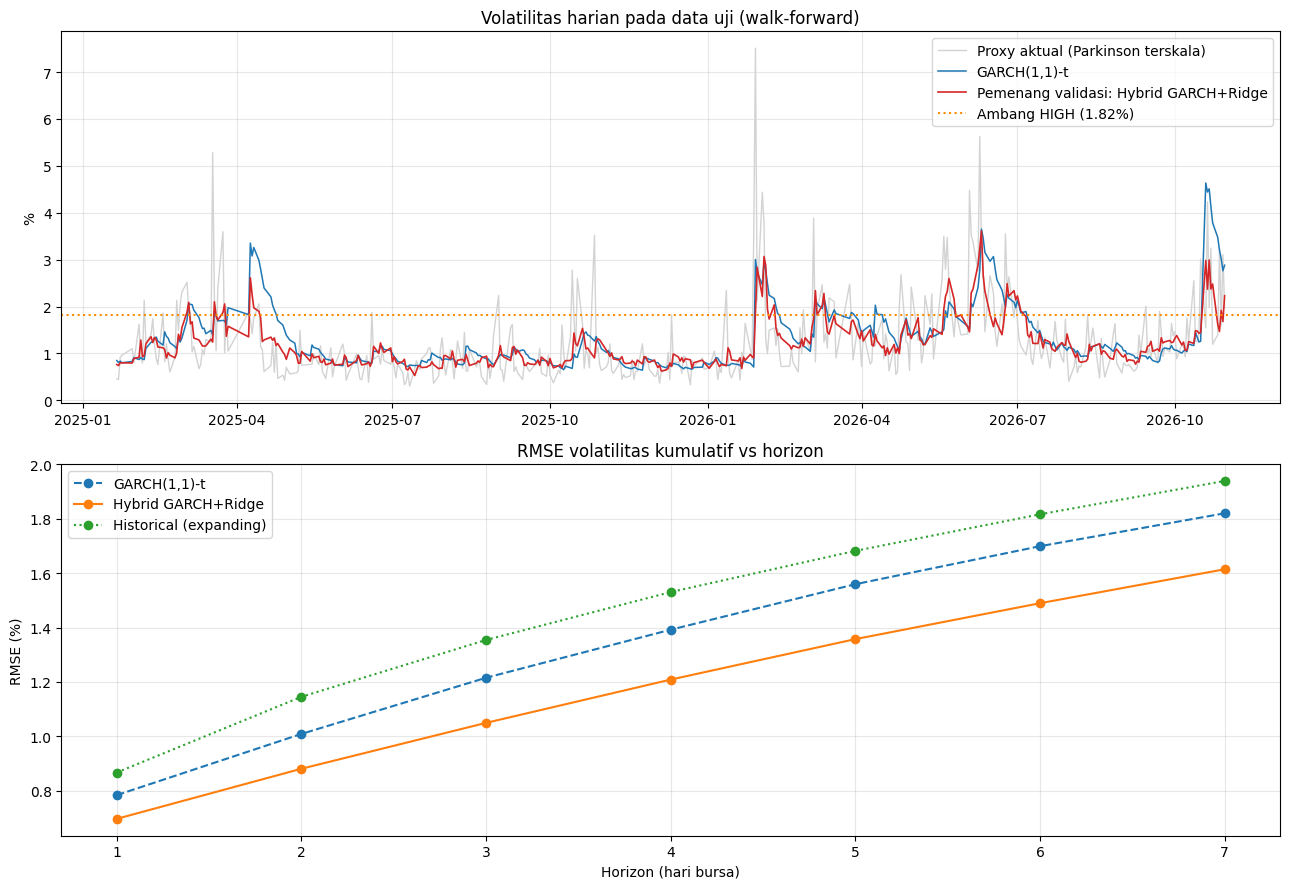

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(13, 9))
d_te = T.index[i_va:n_real]
ax[0].plot(d_te, np.sqrt(y_te_tv), color="lightgray", lw=1.0, label="Proxy aktual (Parkinson terskala)")
ax[0].plot(d_te, np.sqrt(test_fc["GARCH(1,1)-t"]), color="tab:blue", lw=1.1, label="GARCH(1,1)-t")
ax[0].plot(d_te, np.sqrt(test_fc[winner_vol]), color="tab:red", lw=1.2, label=f"Pemenang validasi: {winner_vol}")
ax[0].axhline(tau, color="darkorange", ls=":", label=f"Ambang HIGH ({tau:.2f}%)")
ax[0].set_title("Volatilitas harian pada data uji (walk-forward)"); ax[0].set_ylabel("%"); ax[0].legend(); ax[0].grid(alpha=.3)
hs = np.arange(1, CFG["HORIZON"] + 1)
for n, st in [("GARCH(1,1)-t", "--"), (winner_vol, "-"), ("Historical (expanding)", ":")]:
    ax[1].plot(hs, mh_rmse.loc[n].values, st, marker="o", label=n)
ax[1].set_title("RMSE volatilitas kumulatif vs horizon"); ax[1].set_xlabel("Horizon (hari bursa)"); ax[1].set_ylabel("RMSE (%)")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(os.path.join(CFG["OUT_DIR"], "forecast_diagnostics.png"), dpi=110)
plt.show()

## 11. Prediksi produksi 1–7 hari + JSON (deterministik)

Model dilatih ulang pada **seluruh** data, lalu hari bursa berikutnya diprediksi dari baris fitur hari-depan.
* Volatilitas: model pemenang validasi, lalu mean-reversion GARCH (skala sama).
* Return: untuk h=1 model ML hanya jika lolos gerbang; selain itu (dan untuk h≥2) = rata-rata historis. Tidak ada klaim arah jika tidak ada bukti.
* Harga: median = `close_terakhir × exp(return kumulatif)`, dengan **interval 95%** (pendekatan normal pada volatilitas kumulatif).
* Tanggal target memakai kalender kerja + `IDX_HOLIDAYS` (isi sendiri dari kalender resmi BEI).
* JSON **tanpa timestamp**; berisi sidik jari data. Dengan data dan seed sama, isinya identik byte-per-byte.

In [13]:
def jclean(o):
    if isinstance(o, dict): return {k: jclean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jclean(v) for v in o]
    if isinstance(o, (float, np.floating)): return None if not np.isfinite(o) else round(float(o), 4)
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o

def build_payload():
    st_v, st_r = {}, {}
    fcv, auxv = wf_vol(n_real, n_real + 1, best_vol_specs, st_v)
    h1_var = float(fcv[winner_vol][0])
    unc = float(auxv["uncond"][0]); per = float(np.clip(auxv["persist"][0], 0.0, 0.9999))
    if winner_vol in FLAT:
        paths = [h1_var] * CFG["HORIZON"]
    else:
        paths = [unc + per ** (k - 1) * (h1_var - unc) for k in range(1, CFG["HORIZON"] + 1)]
    mean_d = float(MEANX[n_real])
    ret1 = mean_d
    if ml_return_enabled:
        fcr = wf_ret(n_real, n_real + 1, {winner_ret: best_ret_specs[winner_ret]}, st_r)
        ret1 = float(fcr[winner_ret][0])

    base_date = T.index[n_real - 1]
    last_close = float(CLOSE[n_real - 1])
    dates = pd.bdate_range(base_date + pd.Timedelta(days=1), periods=CFG["HORIZON"], freq="C",
                           holidays=CFG["IDX_HOLIDAYS"])
    rows, cum_var, cum_mu = [], 0.0, 0.0
    for k, (d, v) in enumerate(zip(dates, paths), start=1):
        mu_k = ret1 if k == 1 else mean_d
        cum_var += v; cum_mu += mu_k
        cum_sd = float(np.sqrt(cum_var))
        vol = float(np.sqrt(v))
        rows.append({
            "horizon_step": k, "target_date": str(d.date()),
            "forecast_variance_pct2": v, "forecast_volatility_pct": vol,
            "annualized_volatility_pct": vol * np.sqrt(252.0),
            "risk_regime": "HIGH" if vol > tau else "NORMAL",
            "expected_log_return_pct": mu_k,
            "cumulative_expected_return_pct": cum_mu,
            "median_close_price": last_close * np.exp(cum_mu / 100.0),
            "price_interval_95": [last_close * np.exp((cum_mu - 1.96 * cum_sd) / 100.0),
                                  last_close * np.exp((cum_mu + 1.96 * cum_sd) / 100.0)],
            "prob_up_vs_last_close": float(stats.norm.cdf(cum_mu / cum_sd)),
            "direction_signal": ("UP" if mu_k >= 0 else "DOWN") if (k == 1 and ml_return_enabled) else "NO_SIGNAL",
        })
    tv_, tr_ = tab_A.loc[winner_vol], tab_R.loc[winner_ret if winner_ret != "Rata-rata historis" else "Rata-rata historis"]
    payload = {
        "metadata": {
            "service": "IHSG-Forecasting-Engine", "version": "4.0.0", "ticker": "^JKSE",
            "base_date": str(base_date.date()), "last_close": last_close,
            "data_fingerprint_sha256": DATA_FP, "seed": SEED,
            "train_val_test_days": [int(i_tr), int(i_va - i_tr), int(n_real - i_va)],
            "refit_every_days": CFG["REFIT_EVERY"], "c_train": c_train, "stress_tau_vol_pct": tau,
            "usage_note": "Jalankan setelah penutupan pasar AS dan sebelum pembukaan BEI. Bukan saran investasi.",
        },
        "model_selection": {
            "volatility": {
                "selected_model": winner_vol, "selection": "QLIKE terendah pada data validasi (walk-forward)",
                "hyperparameters": best_vol_cfg.get(winner_vol),
                "validation_qlike": float(val_summary[winner_vol]), "test_qlike": float(tv_["QLIKE"]),
                "test_qlike_garch": float(tab_A.loc["GARCH(1,1)-t", "QLIKE"]),
                "dm_p_vs_garch": float(tv_["p vs GARCH"]) if winner_vol != "GARCH(1,1)-t" else None,
                "test_rmse_vol_pct": float(tv_["RMSE Vol (%)"]),
                "high_regime_recall": float(tv_["Recall HIGH"]), "high_regime_auc": float(tv_["AUC HIGH"]),
            },
            "return": {
                "validation_winner": winner_ret, "ml_gate_passed": bool(ml_return_enabled),
                "used_in_production": winner_ret if ml_return_enabled else "Rata-rata historis",
                "test_r2_oos_vs_hist_mean": float(tr_["R2_OS vs Rata2 Historis"]),
                "test_clark_west_p": float(tr_["p Clark-West (1 sisi)"]),
                "test_directional_accuracy_pct": float(tr_["Akurasi Arah (%)"]),
                "baseline_always_up_pct": float(tr_["Baseline Selalu-Naik (%)"]),
            },
        },
        "forecast_horizons_1_to_7_days": rows,
        "multi_day_summary": {
            "cumulative_7day_volatility_pct": float(np.sqrt(cum_var)),
            "cumulative_7day_expected_return_pct": cum_mu,
            "median_close_7d": last_close * np.exp(cum_mu / 100.0),
        },
    }
    bundle = dict(config=CFG, feature_names=feature_names, ret_features=ret_features, vol_features=vol_features,
                  c_train=c_train, tau=tau, winner_vol=winner_vol, winner_ret=winner_ret,
                  ml_return_enabled=ml_return_enabled, vol_store=st_v, ret_store=st_r)
    return jclean(payload), bundle

payload, bundle = build_payload()
payload_text = json.dumps(payload, indent=2, ensure_ascii=False, sort_keys=False)
atomic_write_text(os.path.join(CFG["OUT_DIR"], "azure_function_payload_7d.json"), payload_text)
joblib.dump(bundle, os.path.join(CFG["OUT_DIR"], "model_bundle.joblib.tmp"))
os.replace(os.path.join(CFG["OUT_DIR"], "model_bundle.joblib.tmp"), os.path.join(CFG["OUT_DIR"], "model_bundle.joblib"))
tab_A.round(6).to_csv(os.path.join(CFG["OUT_DIR"], "eval_volatility_test.csv"))
tab_R.round(6).to_csv(os.path.join(CFG["OUT_DIR"], "eval_return_test.csv"))
print(payload_text)

{
  "metadata": {
    "service": "IHSG-Forecasting-Engine",
    "version": "4.0.0",
    "ticker": "^JKSE",
    "base_date": "2026-10-30",
    "last_close": 5057.0498,
    "data_fingerprint_sha256": "c9a73672dbea8e1771cb473173c97afdb142c05ae0e15c981bd04cb6ffda8dce",
    "seed": 42,
    "train_val_test_days": [
      1260,
      420,
      421
    ],
    "refit_every_days": 21,
    "c_train": 1.4626,
    "stress_tau_vol_pct": 1.8213,
    "usage_note": "Jalankan setelah penutupan pasar AS dan sebelum pembukaan BEI. Bukan saran investasi."
  },
  "model_selection": {
    "volatility": {
      "selected_model": "Hybrid GARCH+Ridge",
      "selection": "QLIKE terendah pada data validasi (walk-forward)",
      "hyperparameters": "alpha=100.0",
      "validation_qlike": 0.2405,
      "test_qlike": 0.5095,
      "test_qlike_garch": 0.5753,
      "dm_p_vs_garch": 0.0725,
      "test_rmse_vol_pct": 0.6966,
      "high_regime_recall": 0.4203,
      "high_regime_auc": 0.8162
    },
    "return": {


## 12. Uji idempotensi
Membangun ulang payload dari awal (latih ulang semua model final) harus menghasilkan JSON yang **identik**, dan data cache tidak boleh berubah. Jika gagal, ada sumber ketidakpastian (seed, data, atau state tersembunyi) yang harus dicari.

In [14]:
if CFG["VERIFY_IDEMPOTENT"]:
    sha = lambda s: hashlib.sha256(s.encode("utf-8")).hexdigest()
    payload2, _ = build_payload()
    text2 = json.dumps(payload2, indent=2, ensure_ascii=False, sort_keys=False)
    on_disk = open(os.path.join(CFG["OUT_DIR"], "azure_function_payload_7d.json"), encoding="utf-8").read()
    df_chk, _, _ = load_raw(CFG)   # baca ulang dari file cache
    fp_chk = hashlib.sha256(pd.util.hash_pandas_object(clean_raw(df_chk), index=True).values.tobytes()).hexdigest()
    assert sha(payload_text) == sha(text2) == sha(on_disk), "TIDAK IDEMPOTEN: payload berbeda antar run"
    assert fp_chk == DATA_FP, "TIDAK IDEMPOTEN: data cache berubah"
    print("[OK] Idempoten: payload identik (sha256 =", sha(payload_text)[:16], "...) dan data cache tidak berubah.")

[OK] Idempoten: payload identik (sha256 = 4c23064a5f00403b ...) dan data cache tidak berubah.


## Daftar pustaka
1. Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327. — Bollerslev, T. (1987). A conditionally heteroskedastic time series model for speculative prices and rates of return. *Review of Economics and Statistics*, 69(3), 542–547.
2. Campbell, J. Y., & Thompson, S. B. (2008). Predicting excess stock returns out of sample. *Review of Financial Studies*, 21(4), 1509–1531.
3. Clark, T. E., & West, K. D. (2007). Approximately normal tests for equal predictive accuracy in nested models. *Journal of Econometrics*, 138(1), 291–311.
4. Corsi, F. (2009). A simple approximate long-memory model of realized volatility. *Journal of Financial Econometrics*, 7(2), 174–196.
5. Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics*, 13(3), 253–263. — Harvey, D., Leybourne, S., & Newbold, P. (1997). Testing the equality of prediction mean squared errors. *International Journal of Forecasting*, 13(2), 281–291.
6. Duan, N. (1983). Smearing estimate: A nonparametric retransformation method. *Journal of the American Statistical Association*, 78(383), 605–610.
7. Glosten, L. R., Jagannathan, R., & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *Journal of Finance*, 48(5), 1779–1801.
8. Hansen, P. R., & Lunde, A. (2005). A forecast comparison of volatility models: Does anything beat a GARCH(1,1)? *Journal of Applied Econometrics*, 20(7), 873–889.
9. Parkinson, M. (1980). The extreme value method for estimating the variance of the rate of change. *Journal of Business*, 53(1), 61–65.
10. Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.
11. Pesaran, M. H., & Timmermann, A. (1992). A simple nonparametric test of predictive performance. *Journal of Business & Economic Statistics*, 10(4), 461–465.
12. Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: an analysis and review. *International Journal of Forecasting*, 16(4), 437–450.
13. Welch, I., & Goyal, A. (2008). A comprehensive look at the empirical performance of equity premium prediction. *Review of Financial Studies*, 21(4), 1455–1508.

Opsional untuk riset lanjutan: *Model Confidence Set* (Hansen, Lunde & Nason, 2011, *Econometrica*, 79(2), 453–497) untuk membandingkan banyak model sekaligus.